In [1]:
import matplotlib.pyplot as plt
import numpy as np
import matplotlib.ticker as mticker
import pandas as pd
import seaborn as sns
from scipy.stats import gaussian_kde, wasserstein_distance, ks_2samp, pearsonr, spearmanr
import glob
import os
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import AutoMinorLocator
from sklearn.manifold import trustworthiness
from sklearn.metrics import silhouette_score
from sklearn.neighbors import NearestNeighbors
import umap
from scipy.stats import mannwhitneyu
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import to_rgba
import os
from scipy.spatial import cKDTree
from scipy.sparse.csgraph import connected_components
import matplotlib.colors as mcolors


In [2]:
from picosvg.svg import SVG

def save_flat_svg(fig, path, dpi=500):
    fig.savefig(path, dpi=dpi)
    svg = SVG.parse(path).topicosvg()
    with open(path, "w") as f:
        f.write(svg.tostring())

In [3]:
plt.rcParams.update({
    "font.size": 18,
    "axes.labelsize": 17,
    "xtick.labelsize": 18,
    "ytick.labelsize": 18,
    "legend.fontsize": 18,
})

# Figure Panel #5


=== NH2 ===
threshold 0.10 eV: average % within = 8.90%
threshold 0.20 eV: average % within = 17.10%
threshold 0.30 eV: average % within = 25.25%
threshold 0.50 eV: average % within = 41.49%
threshold 1.00 eV: average % within = 70.45%
pairwise Wasserstein distance (computed_binding_E):
  0,15.csv vs n0,97.csv: 0.4709
  0,15.csv vs n2,09.csv: 0.8638
  n0,97.csv vs n2,09.csv: 0.3951

=== NO2 ===
threshold 0.10 eV: average % within = 4.38%
threshold 0.20 eV: average % within = 8.72%
threshold 0.30 eV: average % within = 12.90%
threshold 0.50 eV: average % within = 21.98%
threshold 1.00 eV: average % within = 42.93%
pairwise Wasserstein distance (computed_binding_E):
  1,69.csv vs 4,14.csv: 1.8070
  1,69.csv vs n0,76.csv: 2.2647
  4,14.csv vs n0,76.csv: 4.0712

=== O ===
threshold 0.10 eV: average % within = 5.53%
threshold 0.20 eV: average % within = 11.00%
threshold 0.30 eV: average % within = 16.62%
threshold 0.50 eV: average % within = 27.30%
threshold 1.00 eV: average % within = 51.

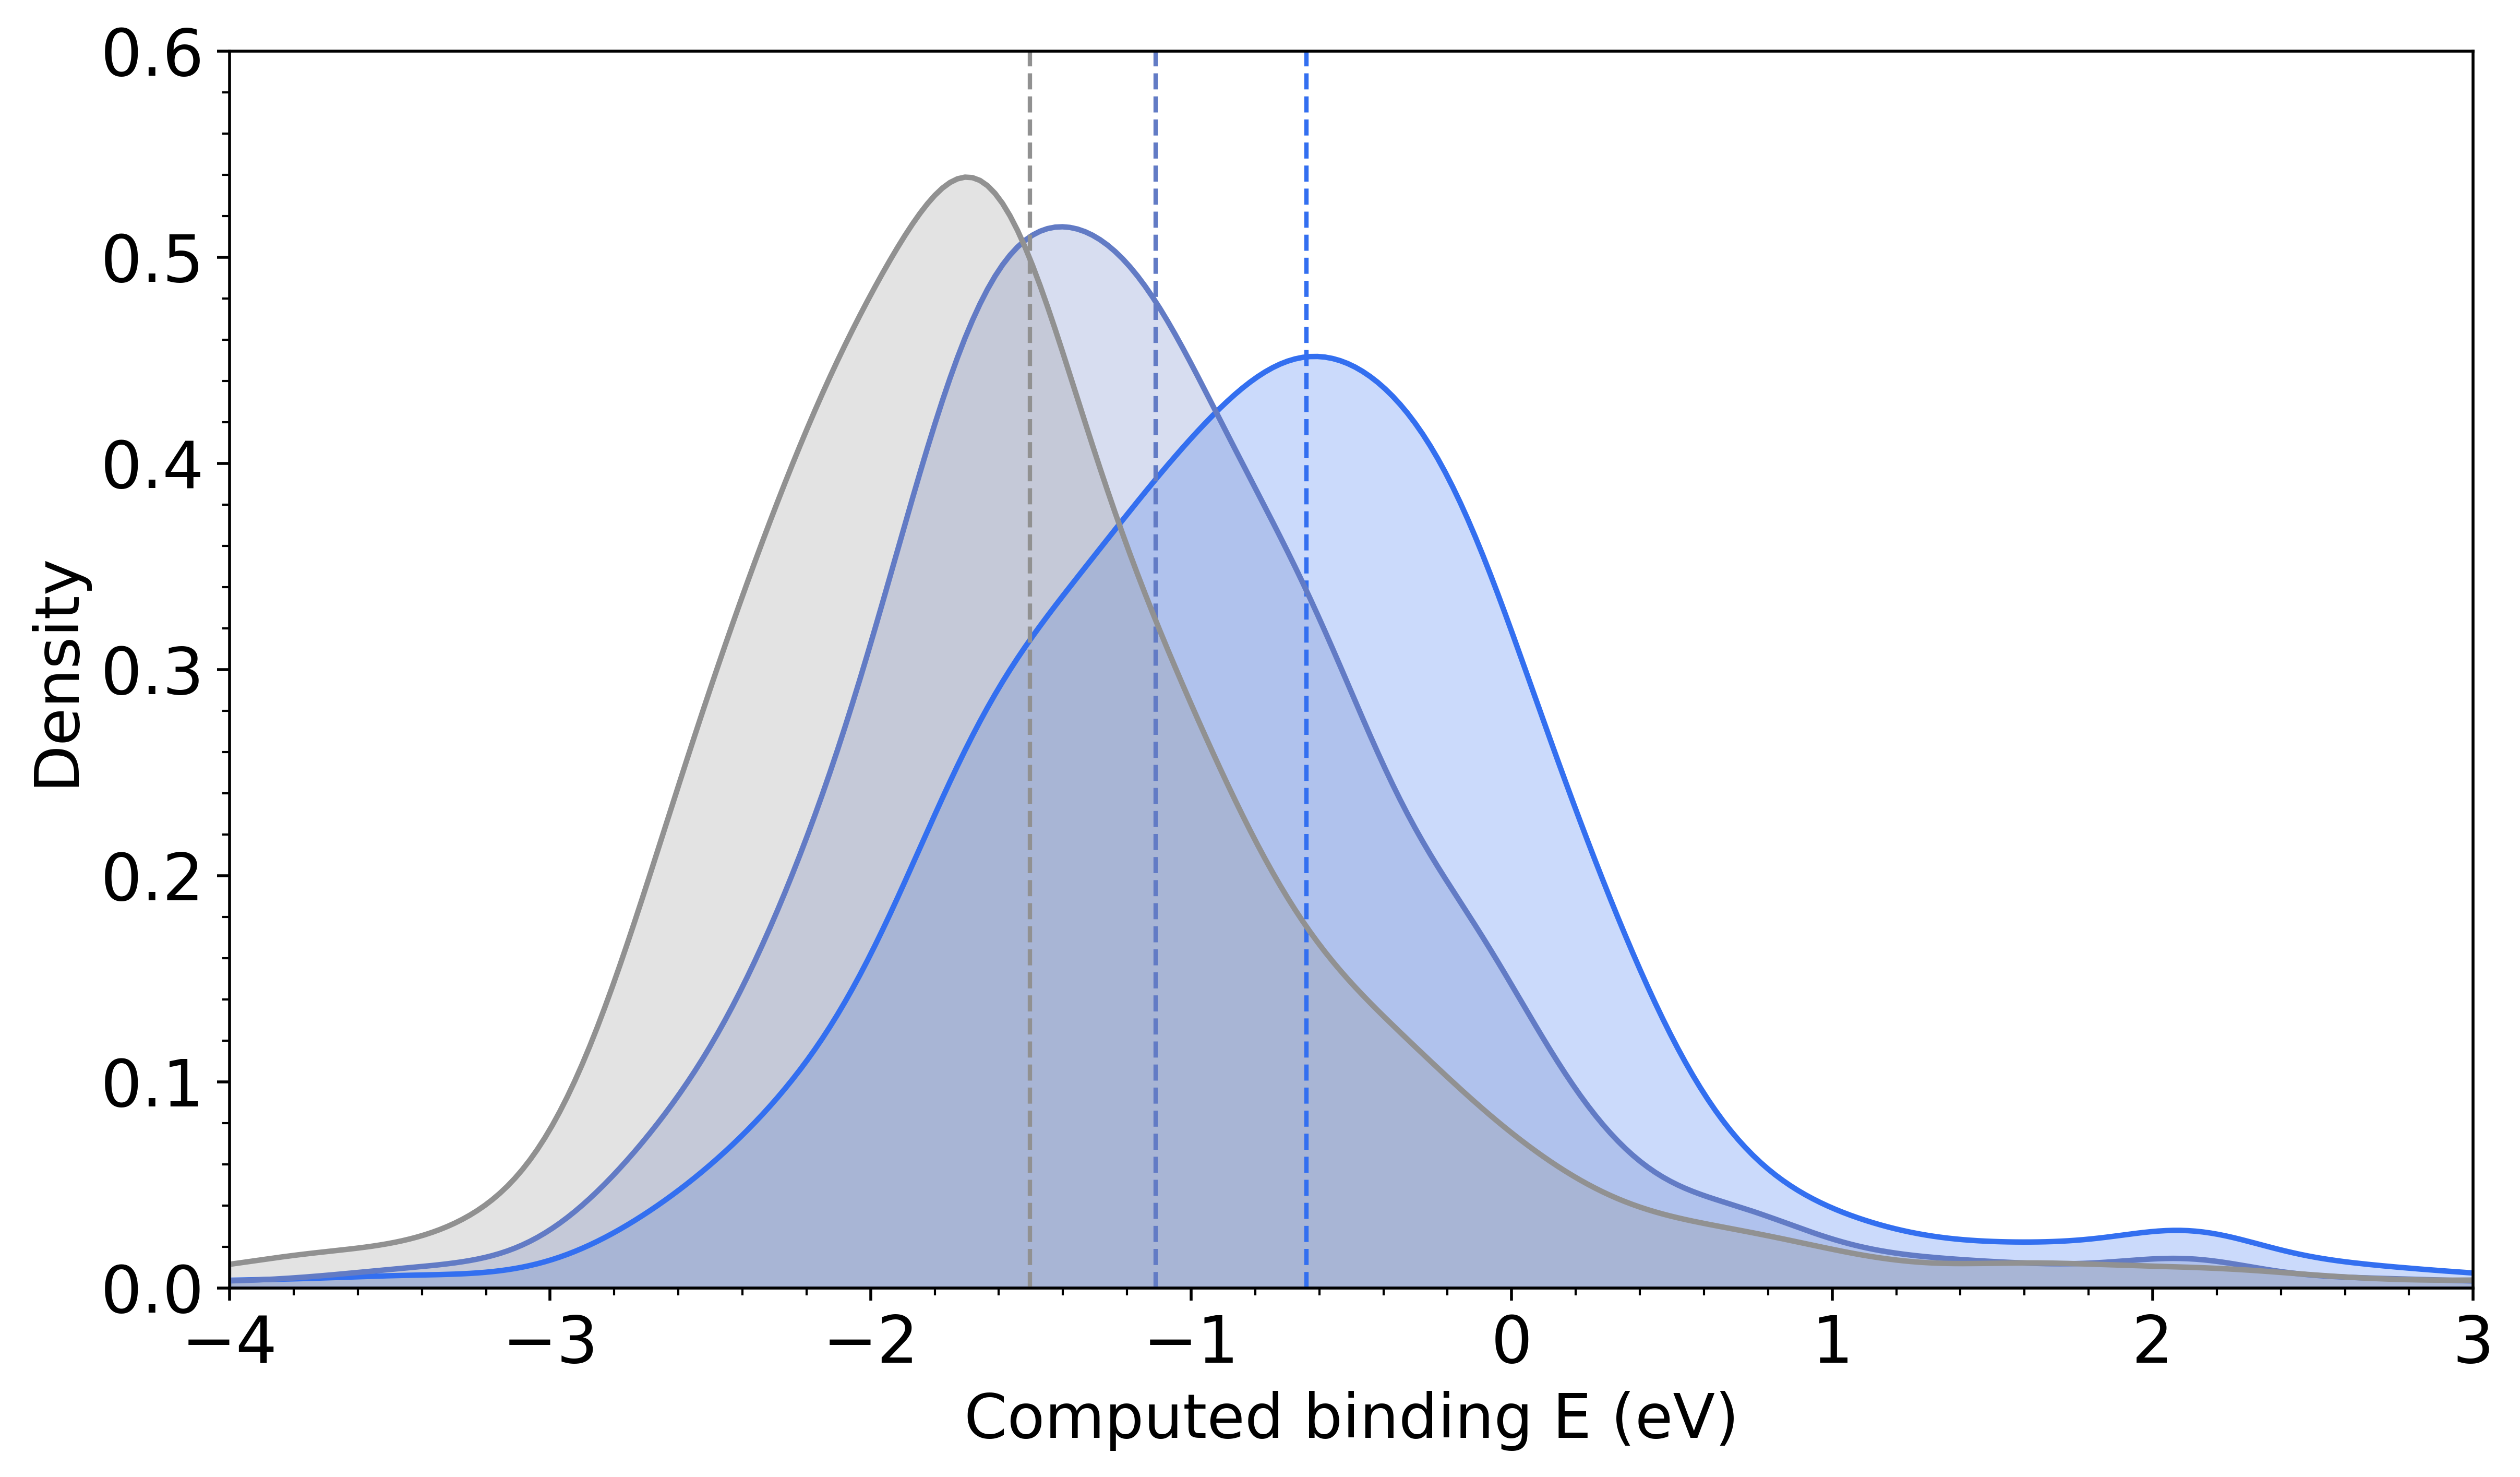

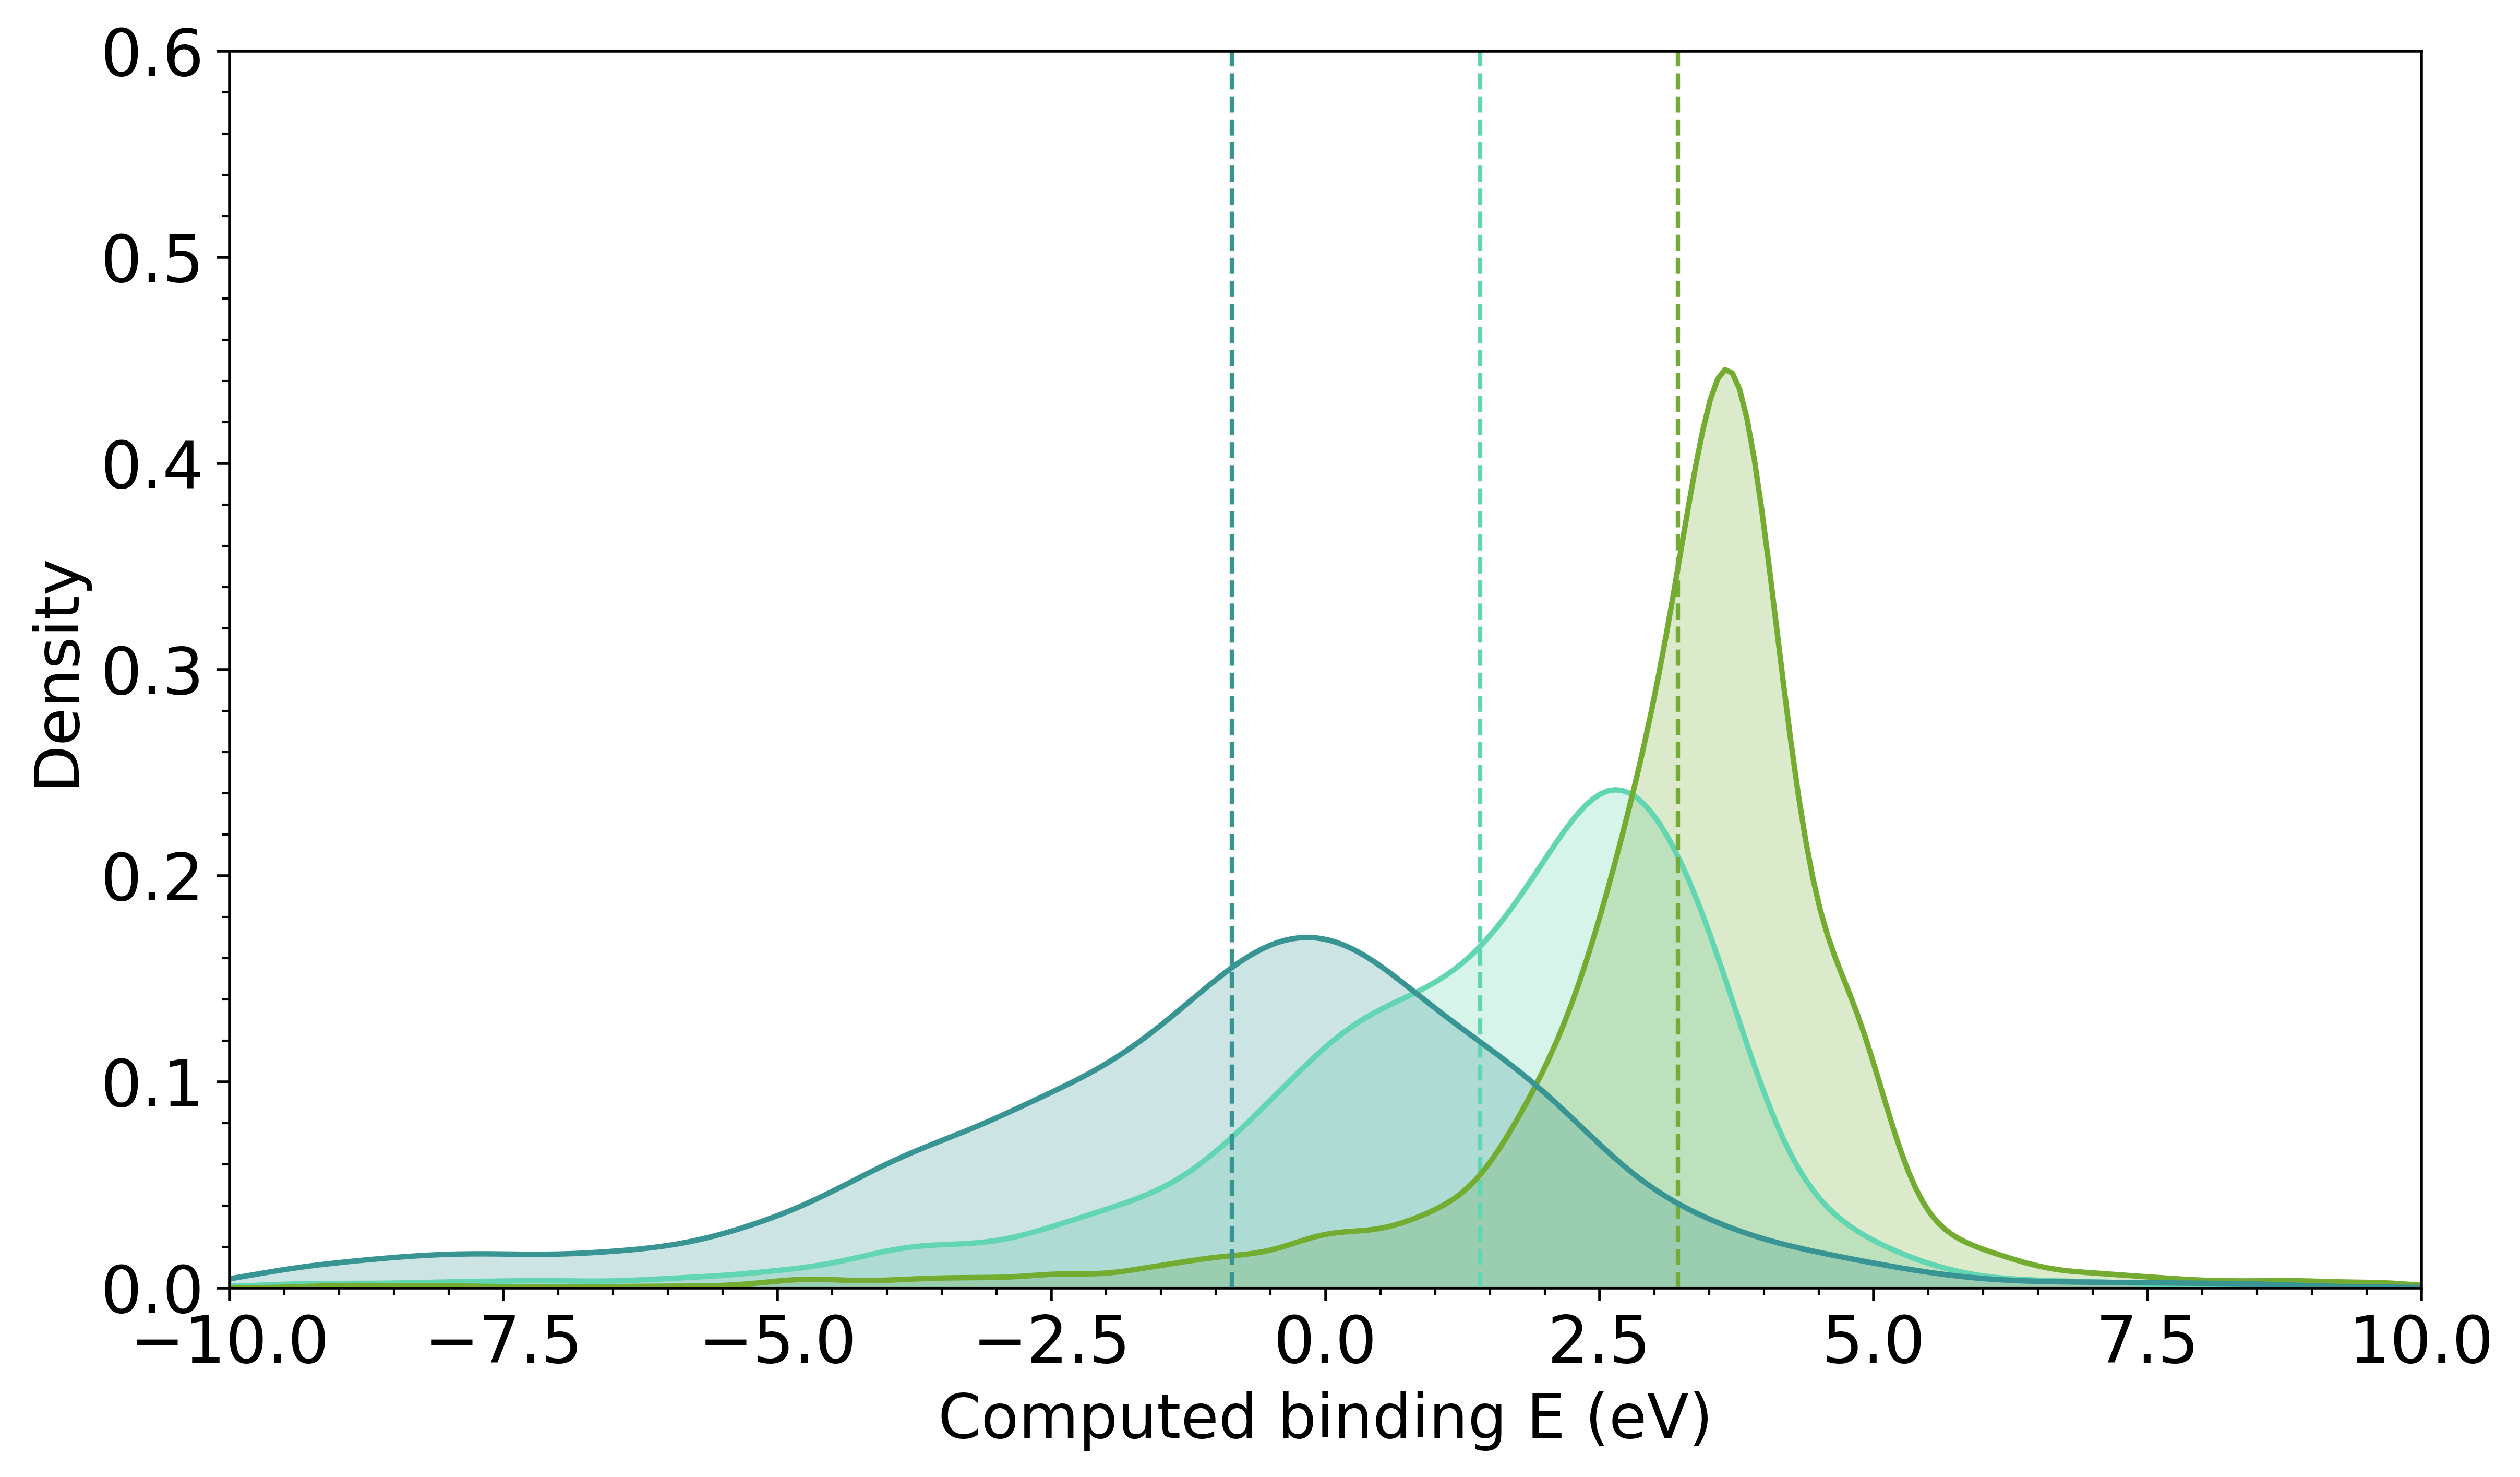

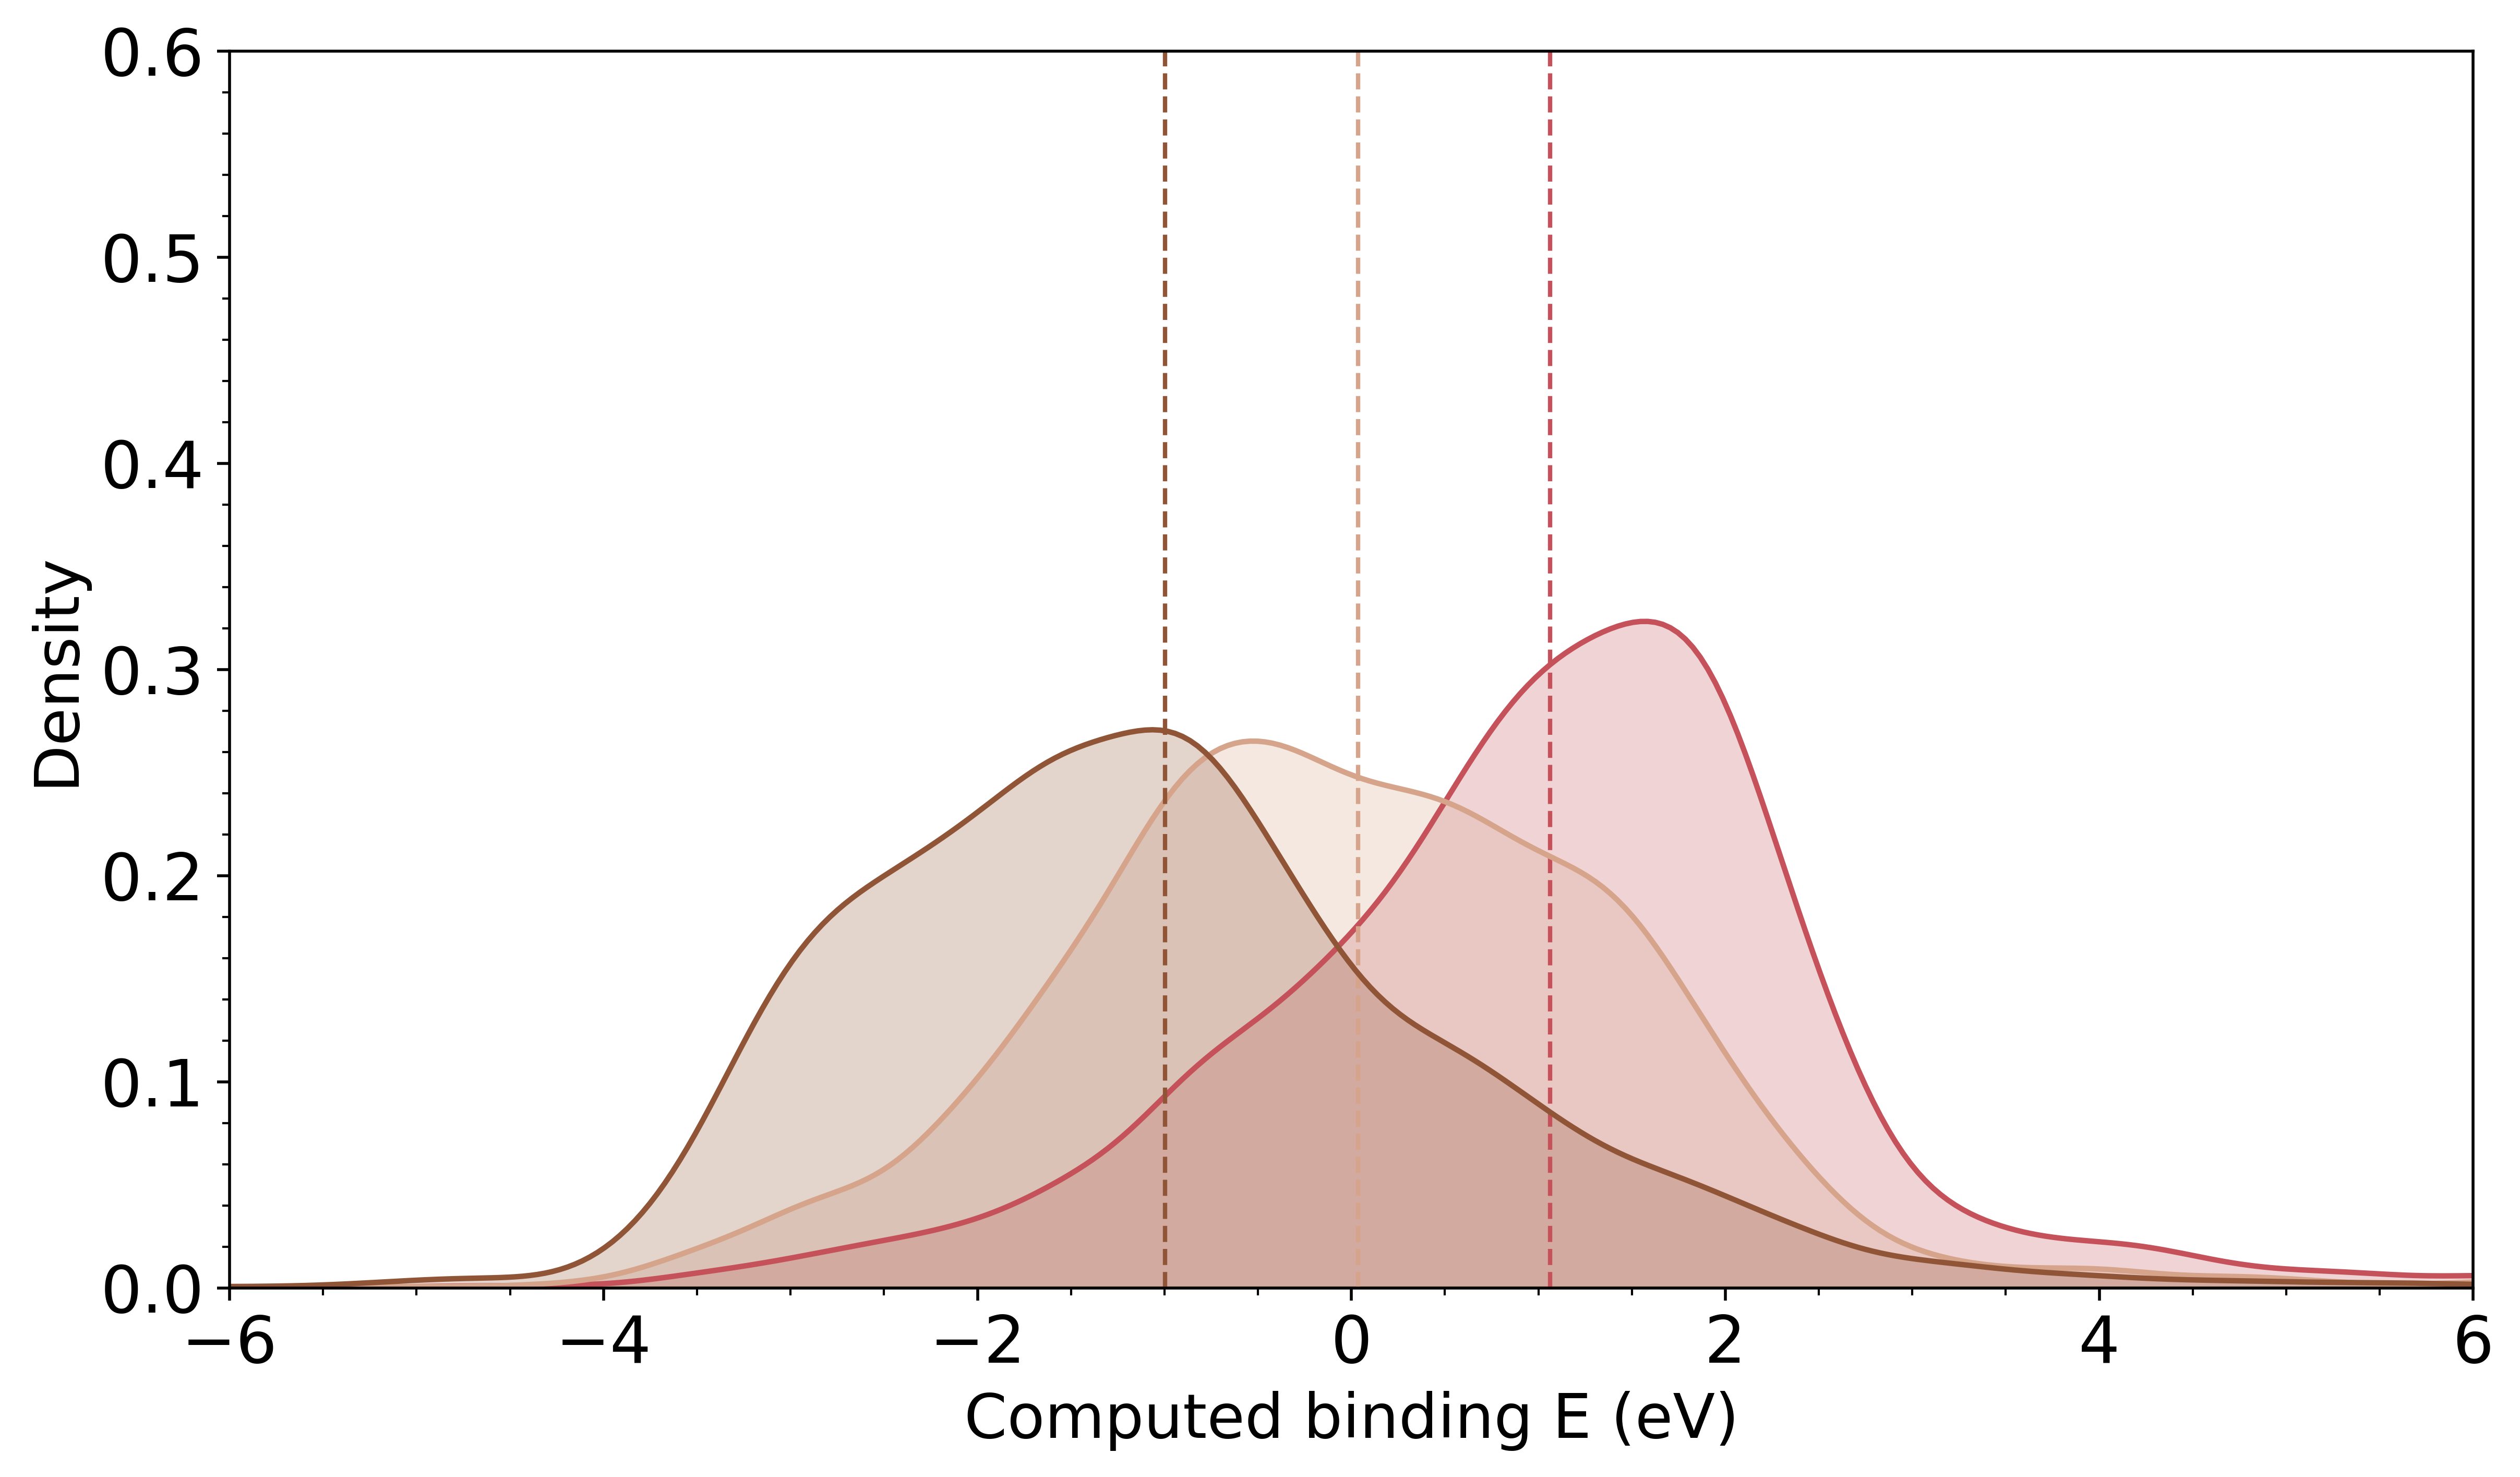

In [4]:
"""
Plot the distribution (KDE) of computed binding energies for the 3 csvs in each
ads_<num> directory under ./data/relaxation_data/, overlaid on a single axis
per adsorbate.

Expected file layout: ./data/relaxation_data/<adsorbate>/*.csv
Expected columns:     target_binding_E, computed_binding_E

Recovered from chat history (2026-07-28, "Visualizing element composition
across binding energies"). See NOTE below re: GRADIENT usage bug.
"""

import glob
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from scipy.stats import gaussian_kde, wasserstein_distance

DATA_DIR = "./data/per_ads_10k/energy_data"

# Discard any row where either column falls outside this range.
FILTER_RANGE = (-10, 10)

ERROR_THRESHOLDS = [0.10, 0.20, 0.30, 0.50, 1.00]

# Manual xlim overrides, keyed by adsorbate dir name. Falls back to
# dynamic min/max (with padding) for any adsorbate not listed here.
XLIM_OVERRIDES = {
    "NH2": (-4, 3),
    "O": (-6, 6),
    "NO2": (-10, 10),
}

# Per-adsorbate color gradients (worst -> best rank within that adsorbate).
COLOR_SCHEME = {
    "NH2": ["#336FF0", "#919191", "#627BC5"],
    "O": ["#905537", "#C5525A", "#D5A48B"],
    "NO2": ["#399494", "#62d5b4", "#73ac31"],
}

adsorbate_dirs = sorted(d for d in glob.glob(os.path.join(DATA_DIR, "*")) if os.path.isdir(d))

for ads_dir in adsorbate_dirs:
    ads_name = os.path.basename(ads_dir)
    csv_paths = sorted(glob.glob(os.path.join(ads_dir, "*.csv")))

    # -------------------------------------------------------------
    # First pass: compute signed error (for ranking/thresholds) and
    # keep computed_binding_E (for plotting) for each csv
    # -------------------------------------------------------------
    errors = {}
    computed_E = {}
    for path in csv_paths:
        df = pd.read_csv(path)
        df = df.dropna(subset=["target_binding_E", "computed_binding_E"])

        mask = df["target_binding_E"].between(*FILTER_RANGE) & df["computed_binding_E"].between(*FILTER_RANGE)
        df = df[mask]

        errors[path] = df["computed_binding_E"] - df["target_binding_E"]
        computed_E[path] = df["computed_binding_E"]

    mean_abs_errors = {path: errors[path].abs().mean() for path in csv_paths}
    order = sorted(csv_paths, key=lambda p: -mean_abs_errors[p])  # worst first
    rank_pos = {path: i / (len(order) - 1) for i, path in enumerate(order)}

    # print threshold percentages (on |error|)
    print(f"\n=== {ads_name} ===")
    for t in ERROR_THRESHOLDS:
        pct_all = [(errors[path].abs() <= t).mean() * 100 for path in csv_paths]
        print(f"threshold {t:.2f} eV: average % within = {np.mean(pct_all):.2f}%")

    print("pairwise Wasserstein distance (computed_binding_E):")
    for i, path_a in enumerate(csv_paths):
        for path_b in csv_paths[i + 1:]:
            w_dist = wasserstein_distance(computed_E[path_a], computed_E[path_b])
            print(f"  {os.path.basename(path_a)} vs {os.path.basename(path_b)}: {w_dist:.4f}")

    # -------------------------------------------------------------
    # Plot
    # -------------------------------------------------------------
    if ads_name in XLIM_OVERRIDES:
        xlim = XLIM_OVERRIDES[ads_name]
    else:
        all_vals = pd.concat(computed_E.values())
        pad = 0.05 * (all_vals.max() - all_vals.min())
        xlim = (all_vals.min() - pad, all_vals.max() + pad)

    fig_g, ax = plt.subplots(figsize=(10, 6), dpi=500)

    x_fine = np.linspace(*xlim, 300)

    for path in csv_paths:
        kde = gaussian_kde(computed_E[path])
        density = kde(x_fine)

        color = LinearSegmentedColormap.from_list(ads_name, COLOR_SCHEME[ads_name])(rank_pos[path])

        ax.plot(x_fine, density, linewidth=1.5, color=color, label=os.path.basename(path))
        ax.fill_between(x_fine, density, alpha=0.25, color=color)
        ax.axvline(computed_E[path].mean(), color=color, linestyle="--", linewidth=1.2)

    ax.minorticks_on()
    ax.set_xlim(*xlim)
    ax.set_ylim(0, 0.60)
    ax.set_yticks(np.arange(0, 0.61, 0.10))
    ax.set_xlabel("Computed binding E (eV)")
    ax.set_ylabel("Density")
    plt.tight_layout()
    save_flat_svg(fig=fig_g, path=f"fig5/panel/{ads_name}_energy_dist.svg")

In [5]:
NOBILITY_RANK = {
    "H": 1,
    "Na": 2,
    "K": 3,
    "Rb": 4,
    "Cs": 5,
    "Ca": 6,
    "Sr": 7,
    "Sc": 8,
    "Y": 9,
    "Ti": 10,
    "Zr": 11,
    "Hf": 12,
    "V": 13,
    "Nb": 14,
    "Ta": 15,
    "Cr": 16,
    "Mo": 17,
    "W": 18,
    "Mn": 19,
    "Tc": 20,
    "Re": 21,
    "Fe": 22,
    "Ru": 23,
    "Os": 24,
    "Co": 25,
    "Rh": 26,
    "Ir": 27,
    "Ni": 28,
    "Pd": 29,
    "Pt": 30,
    "Cu": 31,
    "Ag": 32,
    "Au": 33,
    "Zn": 34,
    "Cd": 35,
    "Hg": 36,
    "Al": 37,
    "Ga": 38,
    "In": 39,
    "Tl": 40,
    "C": 41,
    "Si": 42,
    "Ge": 43,
    "Sn": 44,
    "Pb": 45,
    "N": 46,
    "P": 47,
    "As": 48,
    "Sb": 49,
    "Bi": 50,
    "S": 51,
    "Se": 52,
    "Te": 53,
    "Cl": 54,
}

=== NH2 ===
=== NO2 ===
=== O ===


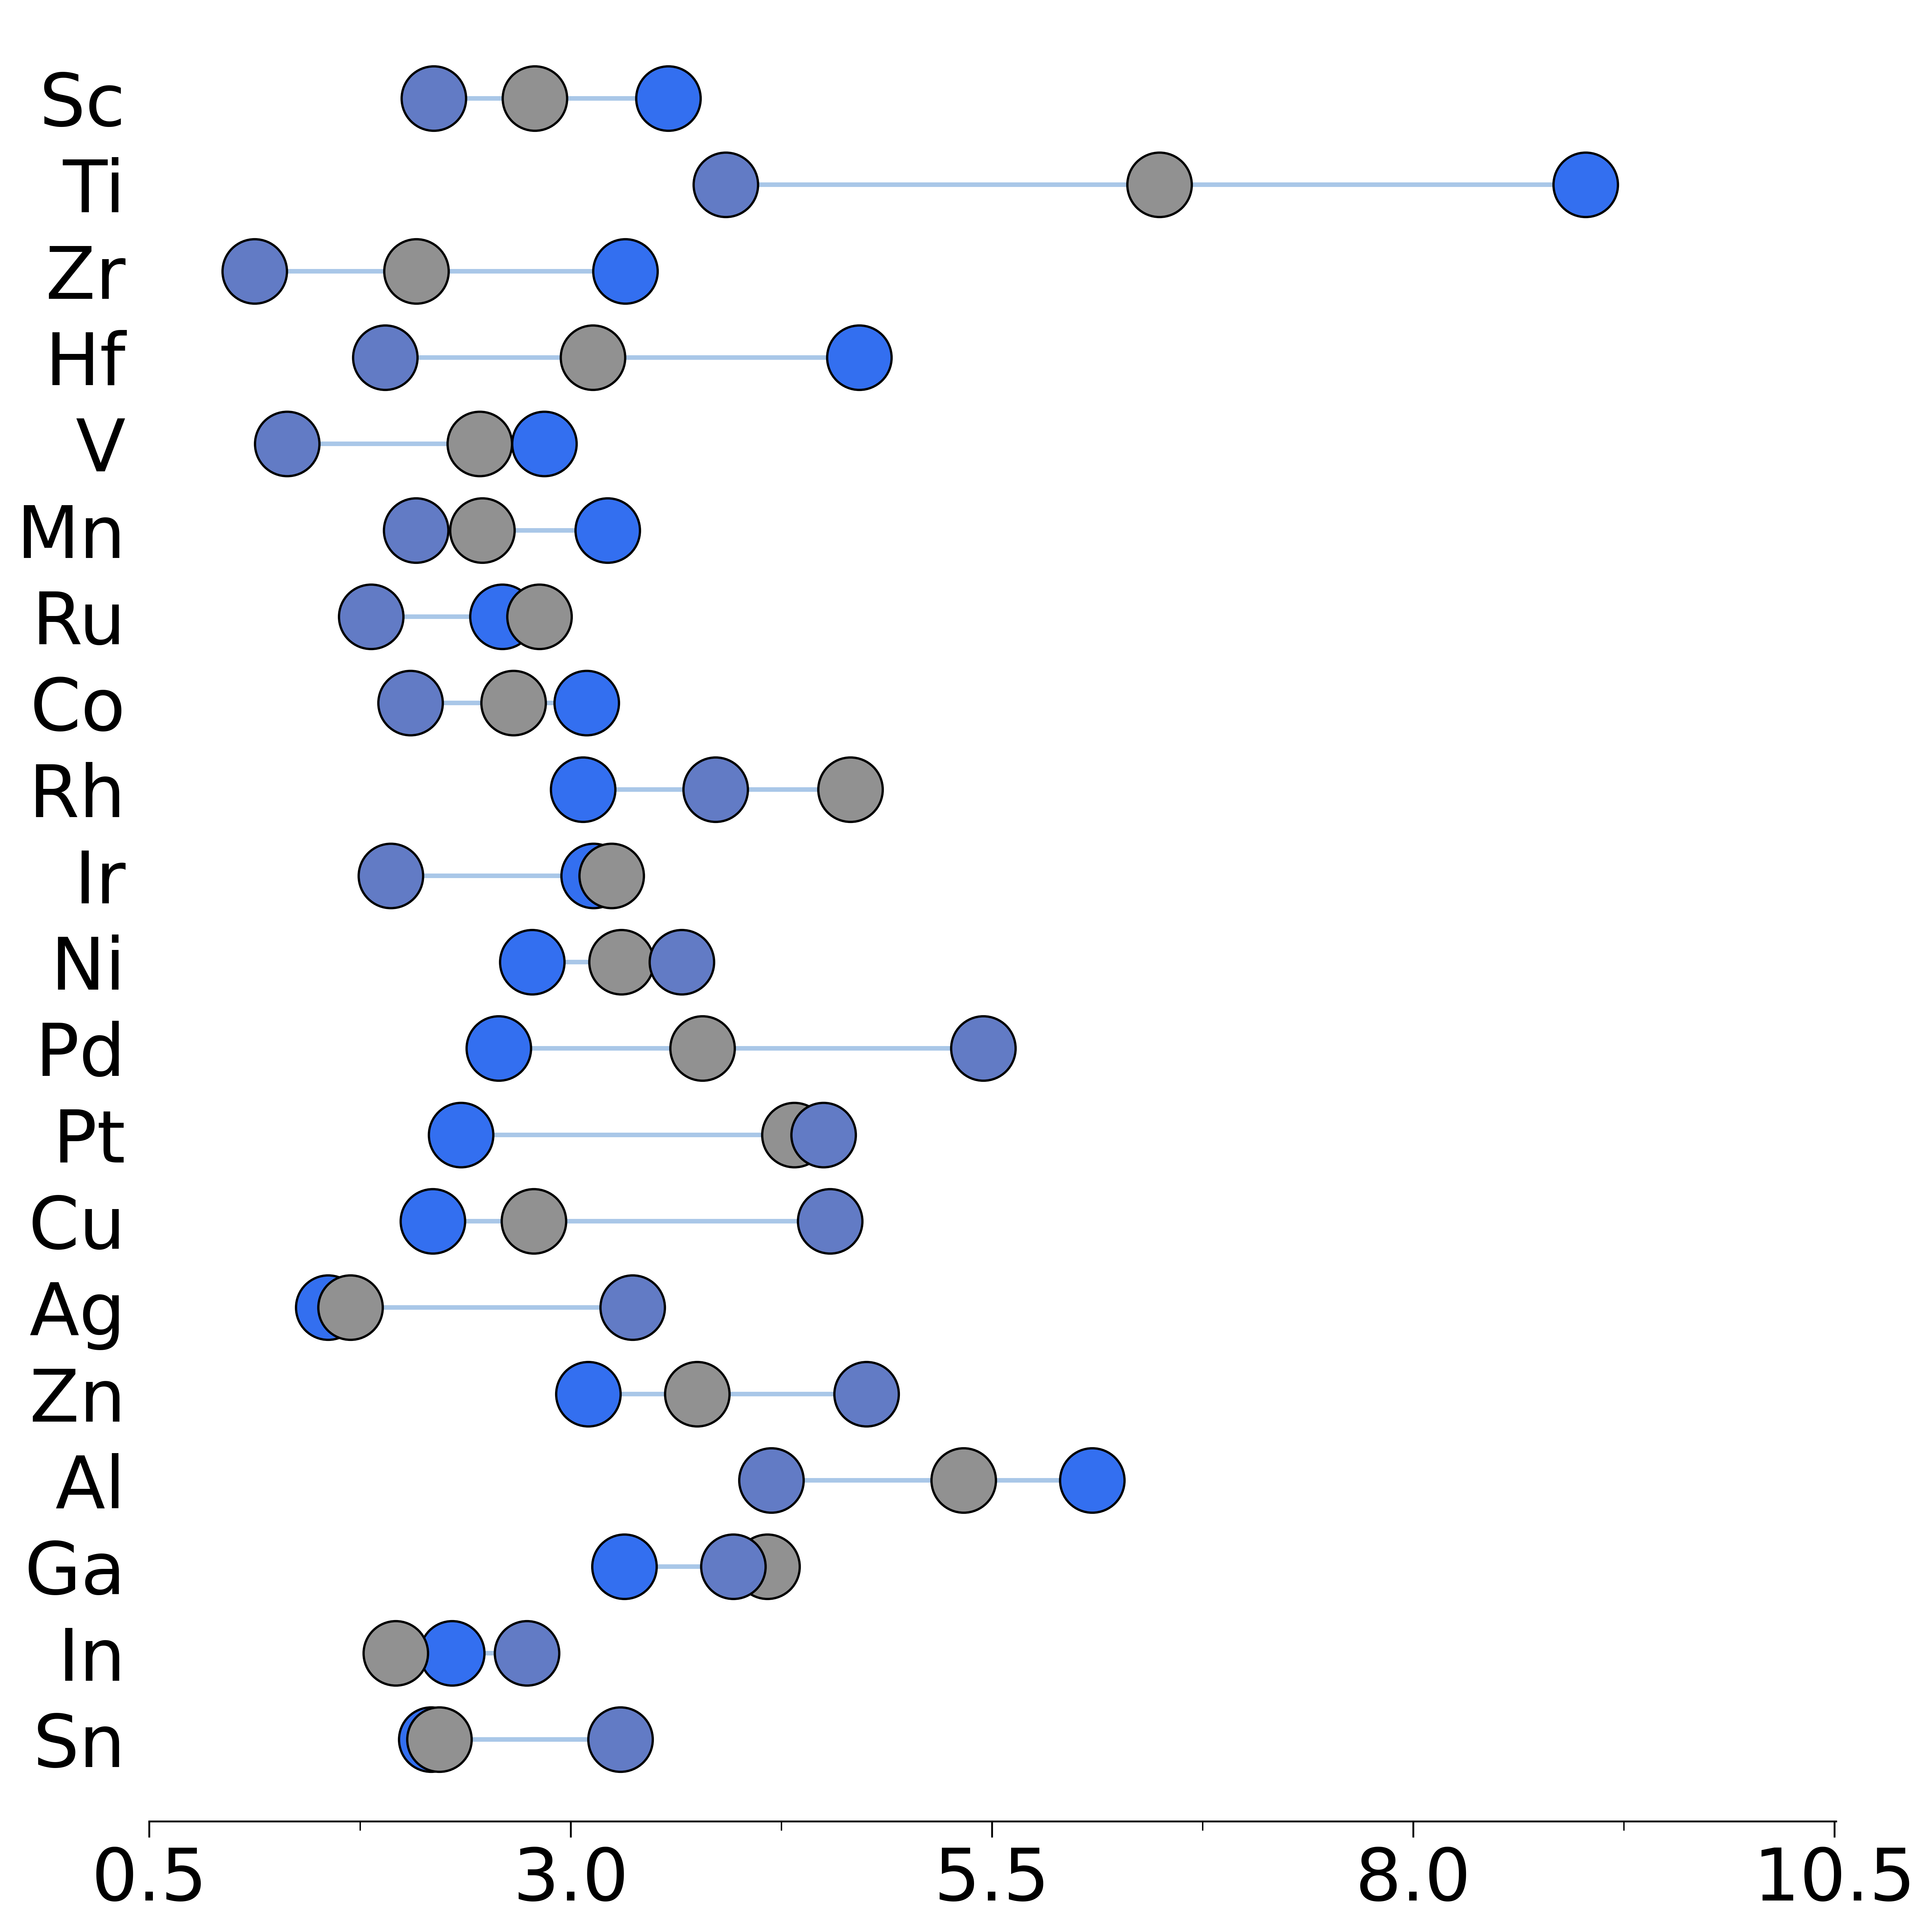

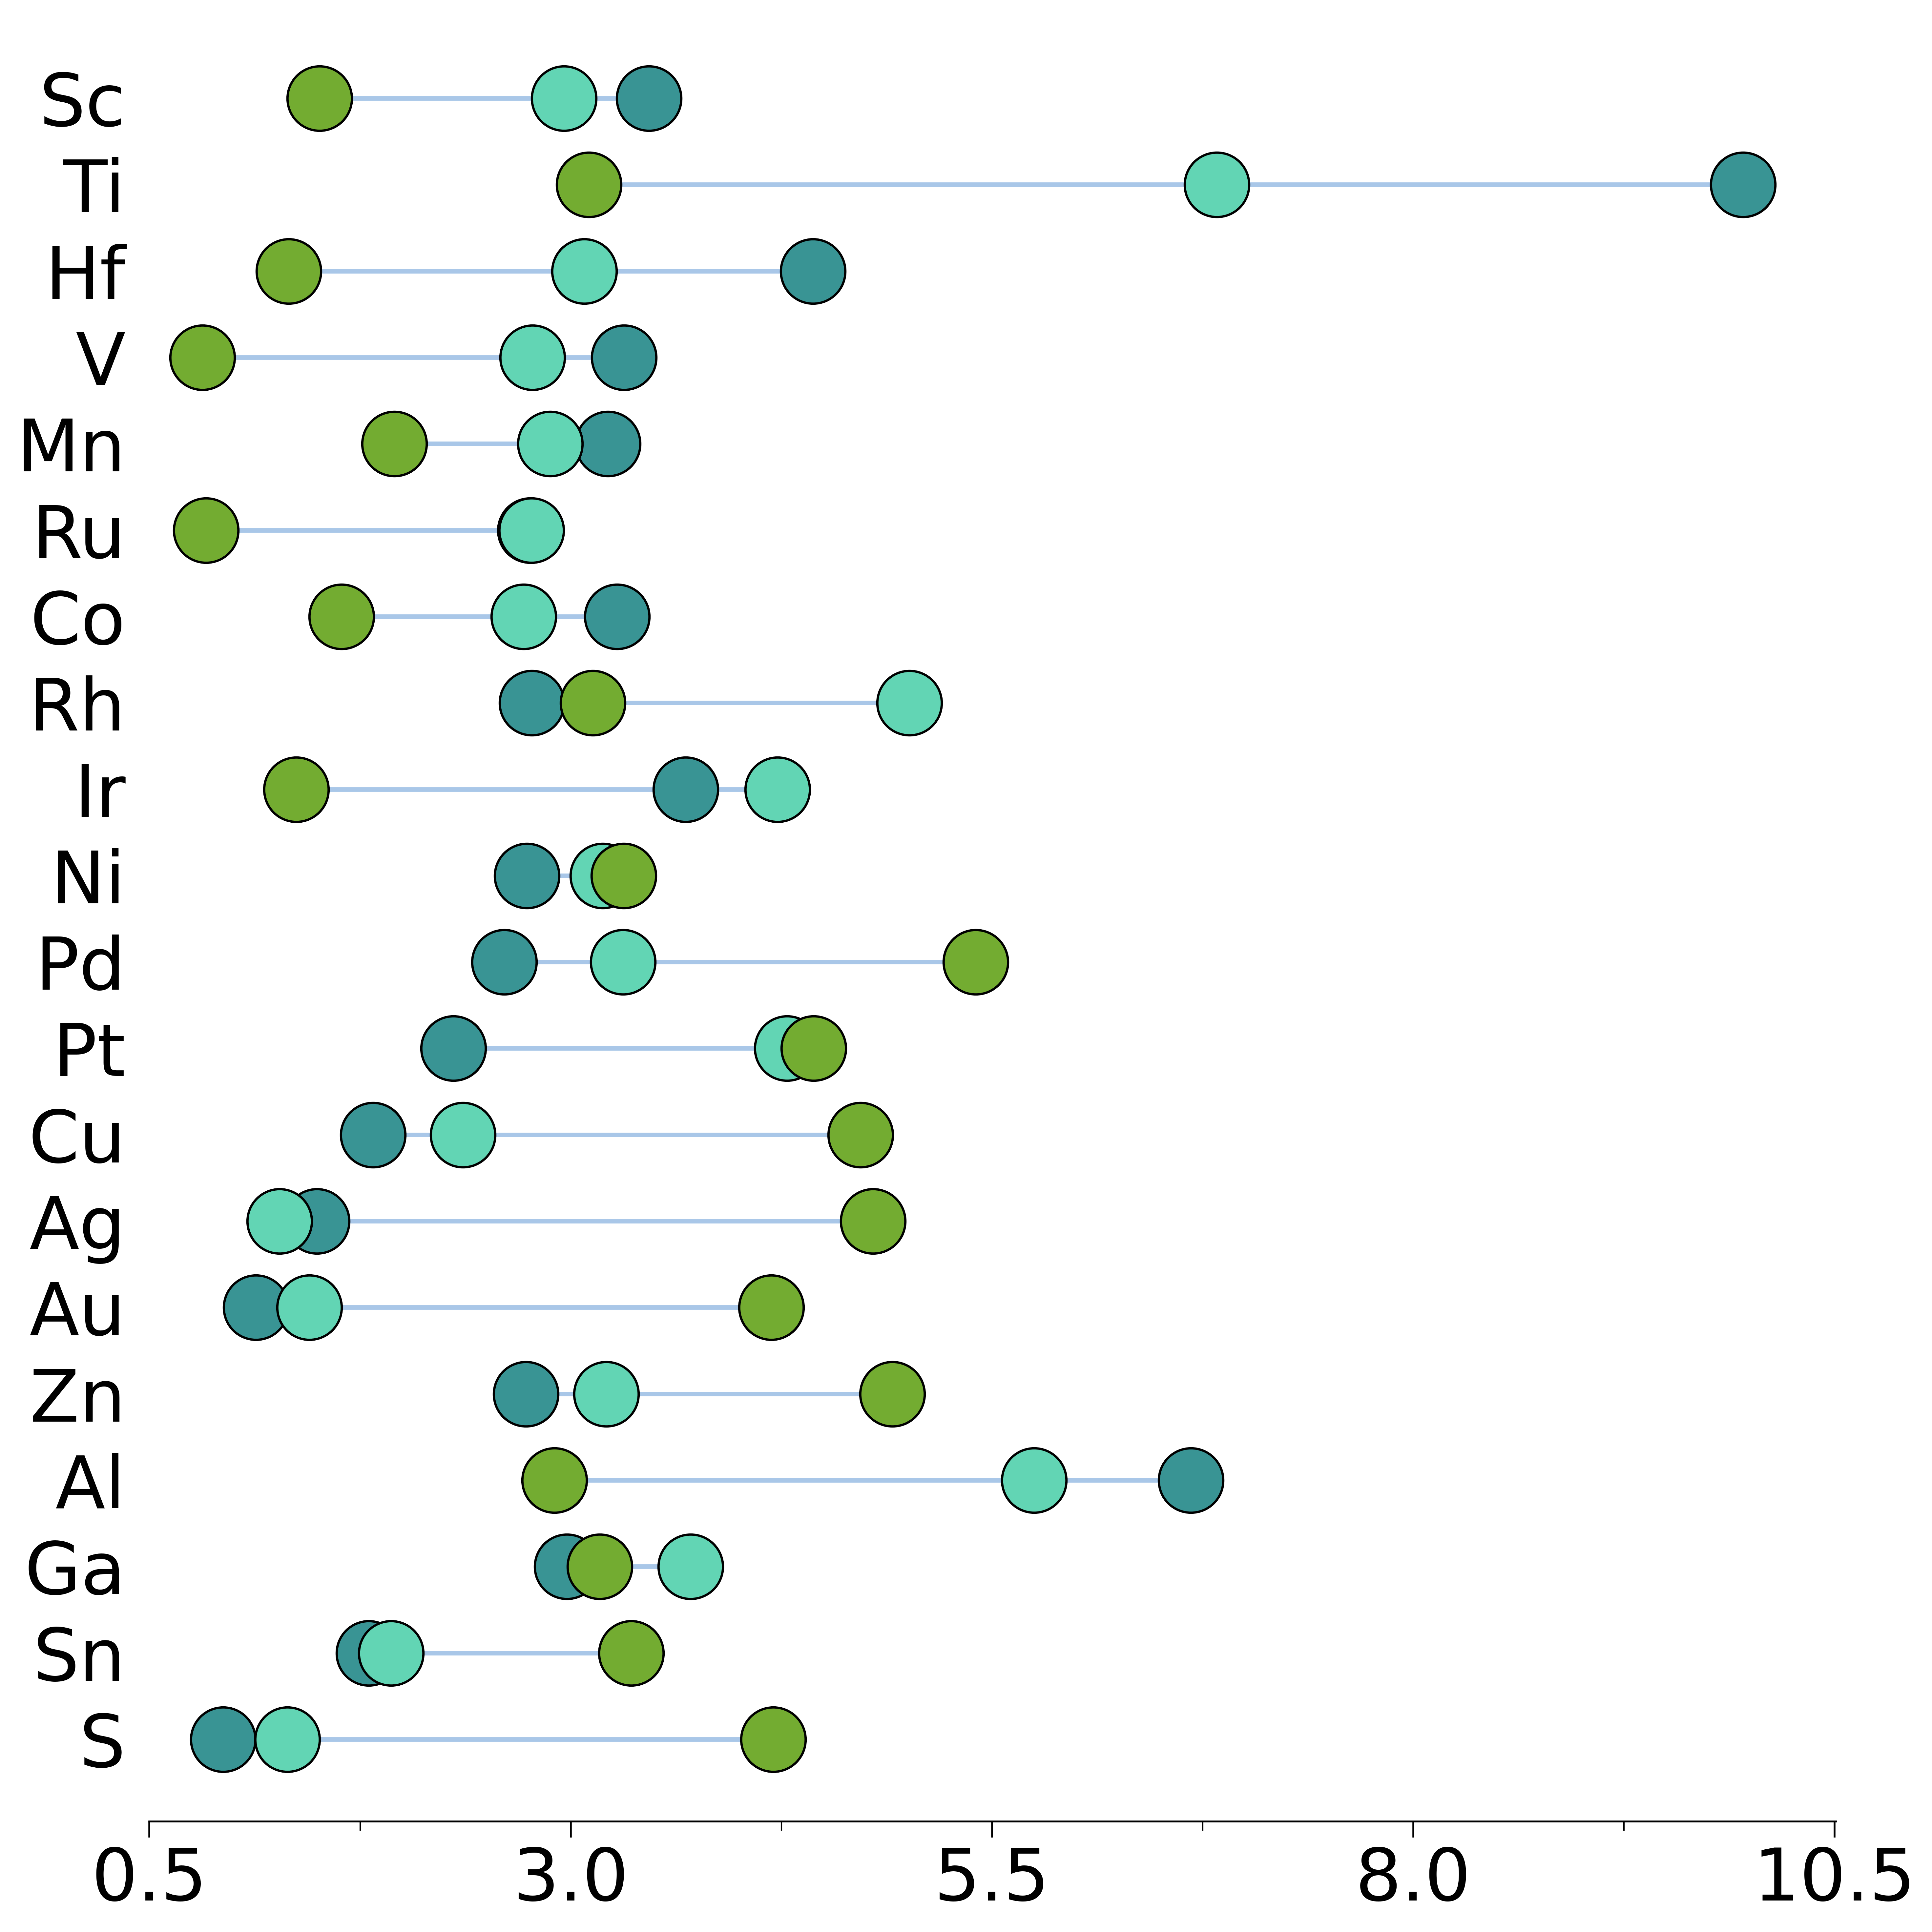

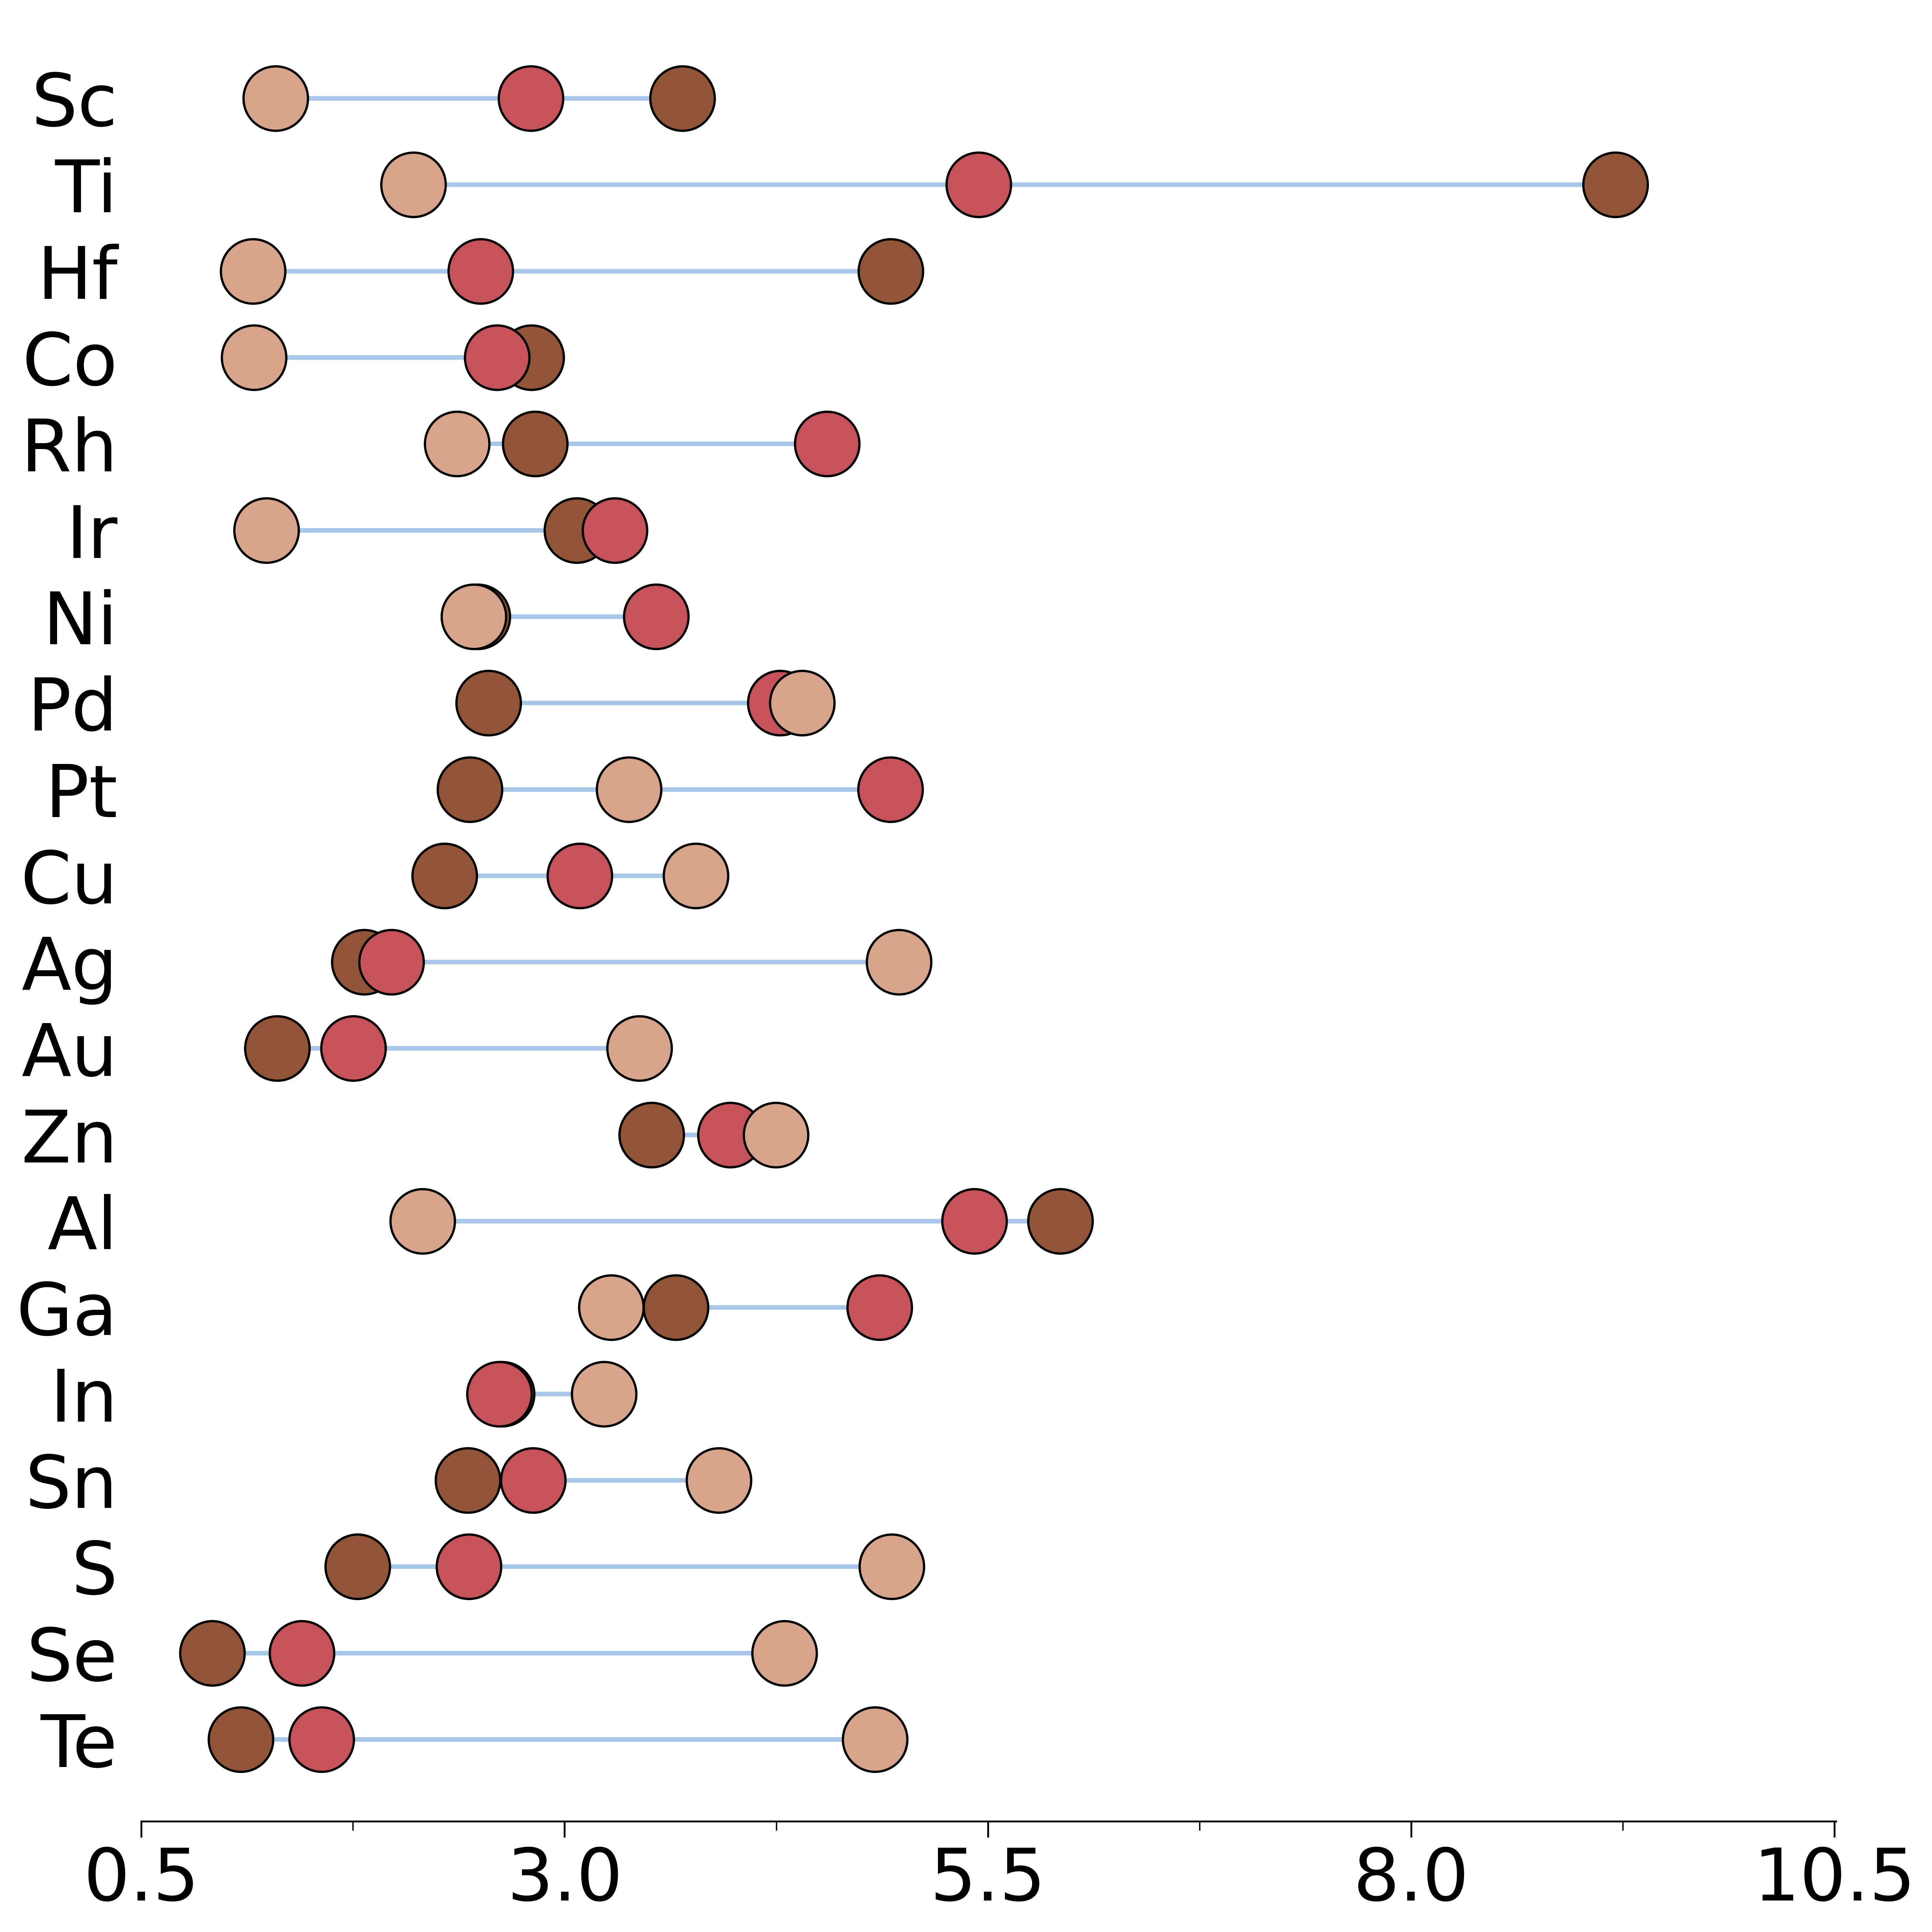

In [6]:
"""
Plot element frequency (fraction of structures containing each element) vs.
conditioning label, as a horizontal range-dot plot: one row per element, a
thin line spanning its min-to-max fraction across labels, with three
colored dots marking the value at each label -- for the csvs in each
ads_<num> directory under ./data/relaxation_data/.

Expected file layout: ./data/relaxation_data/<adsorbate>/*_elements.csv
Filename encodes the conditioning label, e.g. 'n0,97_elements.csv' -> -0.97
Expected columns:     Element, Count

Setup:
  - DATA_DIR: root folder containing one subdirectory per adsorbate, each
    holding exactly 3 "*_elements.csv" files (one per conditioning label).
  - TOP_N_ELEMENTS: caps each plot to the N most frequent elements (by
    total count across all labels for that adsorbate); None plots all.
  - GRADIENT: fixed 3 colors per adsorbate (ordered to match conditioning
    labels sorted ascending), used for the 3 dots per row.
  - DEFAULT_GRADIENT: fallback 3 colors for any adsorbate not in GRADIENT.
  - LINE_COLOR: color of the min-to-max connecting line per row.

`parse_label(path)`:
  Parses a conditioning label out of a filename, e.g. 'n0,97_elements.csv'
  -> -0.97, '2,09_elements.csv' -> 2.09 ('n' prefix = negative, comma =
  decimal point).

`load_ads_dir(ads_dir)`:
  Loads all "*_elements.csv" files in an adsorbate directory into a single
  wide DataFrame: index = element, columns = conditioning label (float,
  sorted ascending), values = fraction of structures containing that
  element at that label. Missing element/label combos are filled with 0.0.

`order_by_nobility(wide, ascending)`:
  Sorts rows by a NOBILITY_RANK lookup (expected to be defined elsewhere in
  the notebook). Elements missing a rank are pushed to the end and their
  names are printed once.

Main flow (per adsorbate directory):
  1. Loads the adsorbate's element-fraction table via load_ads_dir; skips
     the adsorbate if no matching CSVs are found.
  2. If TOP_N_ELEMENTS is set, keeps only the N elements with the highest
     total fraction summed across labels.
  3. Sorts the remaining elements by nobility rank (most noble first,
     top-to-bottom; flip ascending=False -> True to reverse).
  4. Builds the plot: a horizontal line per element spanning its min-to-max
     fraction (%) across the 3 labels, with one colored dot per label
     (from GRADIENT[ads_name] or DEFAULT_GRADIENT), sized/styled and with
     y-axis tick labels set to element names.
  5. Strips the top/right/left spines and left tick marks for a cleaner
     look, then saves the figure as
     "fig3/panel/{ads_name}_element_frequency_range.svg" via
     `save_flat_svg`.
"""

plt.rcParams["font.size"] = 14

DATA_DIR = "./data/per_ads_10k/elemental_data"

# Cap to the N most frequent elements (by total count across all labels for
# that adsorbate). Set to None to plot every element that appears.
TOP_N_ELEMENTS = 20

# Light connecting line spanning each row's min-to-max value.
LINE_COLOR = "#a9c7e8"


def parse_label(path):
    """'n0,97_elements.csv' -> -0.97 ; '2,09_elements.csv' -> 2.09"""
    stem = os.path.basename(path).replace("_elements.csv", "")
    negative = stem.startswith("n")
    stem = stem.lstrip("n")
    value = float(stem.replace(",", "."))
    return -value if negative else value


def load_ads_dir(ads_dir):
    """Return a DataFrame: index=Element, columns=conditioning label (float),
    values=fraction of structures containing that element at that label."""
    csv_paths = sorted(glob.glob(os.path.join(ads_dir, "*_elements.csv")))
    series = {}
    for path in csv_paths:
        label = parse_label(path)
        df = pd.read_csv(path)
        counts = df.set_index("Element")["Count"]
        series[label] = counts / counts.sum()

    wide = pd.DataFrame(series).sort_index(axis=1)  # columns sorted by label value
    return wide.fillna(0.0)


def order_by_nobility(wide, ascending=True):
    """Sort rows by NOBILITY_RANK. Elements missing from the dict (or with a
    None value) are pushed to the end, and their names are printed once so
    gaps in the ranking are easy to spot."""
    ranks = wide.index.map(lambda el: NOBILITY_RANK.get(el))
    missing = [el for el, r in zip(wide.index, ranks) if r is None]
    if missing:
        print(f"  no nobility rank set for: {', '.join(missing)} (sorted last)")

    rank_series = pd.Series(
        [np.inf if r is None else r for r in ranks], index=wide.index
    )
    order = rank_series.sort_values(ascending=ascending).index
    return wide.loc[order]


ads_dirs = sorted(d for d in glob.glob(os.path.join(DATA_DIR, "*")) if os.path.isdir(d))

for ads_dir in ads_dirs:
    ads_name = os.path.basename(ads_dir)
    wide = load_ads_dir(ads_dir)

    if wide.empty:
        print(f"Skipping {ads_name}: no *_elements.csv files found.")
        continue

    if TOP_N_ELEMENTS is not None and len(wide) > TOP_N_ELEMENTS:
        totals = wide.sum(axis=1)
        wide = wide.loc[totals.sort_values(ascending=False).index[:TOP_N_ELEMENTS]]

    print(f"=== {ads_name} ===")
    # sort elements by nobility rank (most noble first, top-to-bottom).
    # flip ascending=False if you'd rather have least-noble at the top.
    wide = order_by_nobility(wide, ascending=False)

    colors = COLOR_SCHEME.get(ads_name)
    y = np.arange(len(wide))

    fig_h, ax = plt.subplots(figsize=(12, 12), dpi=500)

    row_min = wide.min(axis=1).values * 100
    row_max = wide.max(axis=1).values * 100
    ax.hlines(y, row_min, row_max, color=LINE_COLOR, linewidth=2, zorder=1)

    for label, color in zip(wide.columns, colors):
        xi = wide[label].values * 100
        ax.scatter(xi, y, color=color, s=800, label=f"{label:.2f} eV", zorder=3, edgecolors="black")

    ax.set_xlim(0.50, 10.51)
    ax.set_xticks(np.arange(0.50, 10.51, 2.50))
    ax.xaxis.set_minor_locator(AutoMinorLocator(2))
    ax.tick_params(which="major", length=7)
    ax.tick_params(which="minor", length=4)

    ax.set_yticks(y)
    ax.set_yticklabels(wide.index, fontsize=32)
    ax.tick_params(axis="x", labelsize=32)
    #ax.legend()

    for spine in ["top", "right", "left"]:
        ax.spines[spine].set_visible(False)
    ax.tick_params(left=False)

    plt.tight_layout()
    save_flat_svg(fig=fig_h, path=f"fig5/panel/{ads_name}_element_frequency_range.svg")